# ANA 505 - Project Part 01
**Dataset:** `sales_and_customers.csv`
**Topics covered:** Exploratory Data Analysis (EDA), Decision Tree, Linear Regression

---

## Workflow:

1. Setup 
    - libraries
    - Load and inspect the dataset
2. EDA
    - Descriptive statistics  
    - Visualizations (bar charts, histograms, or scatter plots)
3. Decision Tree
    - Build a decision tree model to predict `Customer-Satisfaction` based on other variables
    - visualize, and interpret
4. Regression Analysis
    - Create linear regression model to predict `Annual-Spend` using vars like `age` and `income`.
    - summarize and interpret the model
5. Deliverables
    - PDF
        - Code
        - Visualizations
        - 500 word report

---
## 1. Setup

install and import packages

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import(
    accuracy_score, classification_report,
    mean_squared_error, r2_score
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# Aesthetic defaults
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

load and inspect data

In [2]:
DATA_PATH = '../datasets/sales_and_customers.csv'
df = pd.read_csv(DATA_PATH)

print(f"shape: {df.shape}")
print(f"\nColumn dtypes:")
print(df.dtypes)
print(f"\nMissing values per column:")
print(df.isnull().sum())

shape: (200, 7)

Column dtypes:
CustomerID                 int64
Age                        int64
Income                     int64
Annual_Spend             float64
Number_of_Visits           int64
Preferred_Channel            str
Customer_Satisfaction        str
dtype: object

Missing values per column:
CustomerID               0
Age                      0
Income                   0
Annual_Spend             0
Number_of_Visits         0
Preferred_Channel        0
Customer_Satisfaction    0
dtype: int64


In [3]:
df.head(10)

,CustomerID,Age,Income,Annual_Spend,Number_of_Visits,Preferred_Channel,Customer_Satisfaction
0,4001,49,142212,6396.61,19,Online,High
1,4002,29,132410,4007.13,6,Online,High
2,4003,35,120302,4255.60,17,In-Store,High
3,4004,24,138394,3431.43,3,In-Store,High
4,4005,41,85392,6124.78,3,Online,High
5,4006,29,129319,2255.55,19,Online,High
6,4007,65,65962,9690.73,15,Online,High
7,4008,27,77339,8855.29,7,Online,High
8,4009,31,100642,1635.44,9,Online,High
9,4010,58,40727,7055.83,29,Online,Medium


### 2.1 Quick Column Glossary
| Column | Type | Meaning |
|--------|------|---------|
| `CustomerID` | int | Unique customer identifier (not a feature) |
| `Age` | int | Customer age in years |
| `Income` | int | Annual income (USD) |
| `Annual_Spend` | float | Total spending per year (USD) |
| `Number_of_Visits` | int | Store / website visits per year |
| `Preferred_Channel` | str | Online / In-Store / Mobile |
| `Customer_Satisfaction` | str | High / Medium / Low (**target for Decision Tree**) |

---
## 2. Exploratory Data Analysis (EDA)

### 2.1 Descriptive Statistics

In [4]:
df.describe().round(2)

,CustomerID,Age,Income,Annual_Spend,Number_of_Visits
count,200.00,200.00,200.00,200.00,200.00
mean,4100.50,45.86,92201.74,5338.69,14.72
std,57.88,16.73,34532.06,2743.75,8.72
min,4001.00,18.00,30591.00,504.20,1.00
25%,4050.75,31.00,64263.50,3221.35,7.00
50%,4100.50,45.00,90003.50,5269.09,15.00
75%,4150.25,62.00,123764.25,7747.01,22.00
max,4200.00,74.00,149489.00,9984.84,29.00


In [5]:

# view categorical columns
print('=== Preferred_Channel ===')

preferred_channel = df['Preferred_Channel'].value_counts().to_frame("count")
preferred_channel["percentage"] = (
    (preferred_channel["count"]/preferred_channel["count"].sum())
    .map(lambda p: f"{p: .2%}")
)
print(preferred_channel)

print('\n=== Customer_Satisfaction ===')

satisfaction = df['Customer_Satisfaction'].value_counts().to_frame("count")
satisfaction["percentage"] = (
    (satisfaction["count"]/satisfaction["count"].sum())
    .map(lambda p: f"{p: .2%}")
)
print(satisfaction)

=== Preferred_Channel ===
                   count percentage
Preferred_Channel                  
Online               109     54.50%
In-Store              56     28.00%
Mobile                35     17.50%

=== Customer_Satisfaction ===
                       count percentage
Customer_Satisfaction                  
High                     123     61.50%
Medium                    58     29.00%
Low                       19      9.50%


### 2.2 Distribution of Numerical Variables (Histograms)

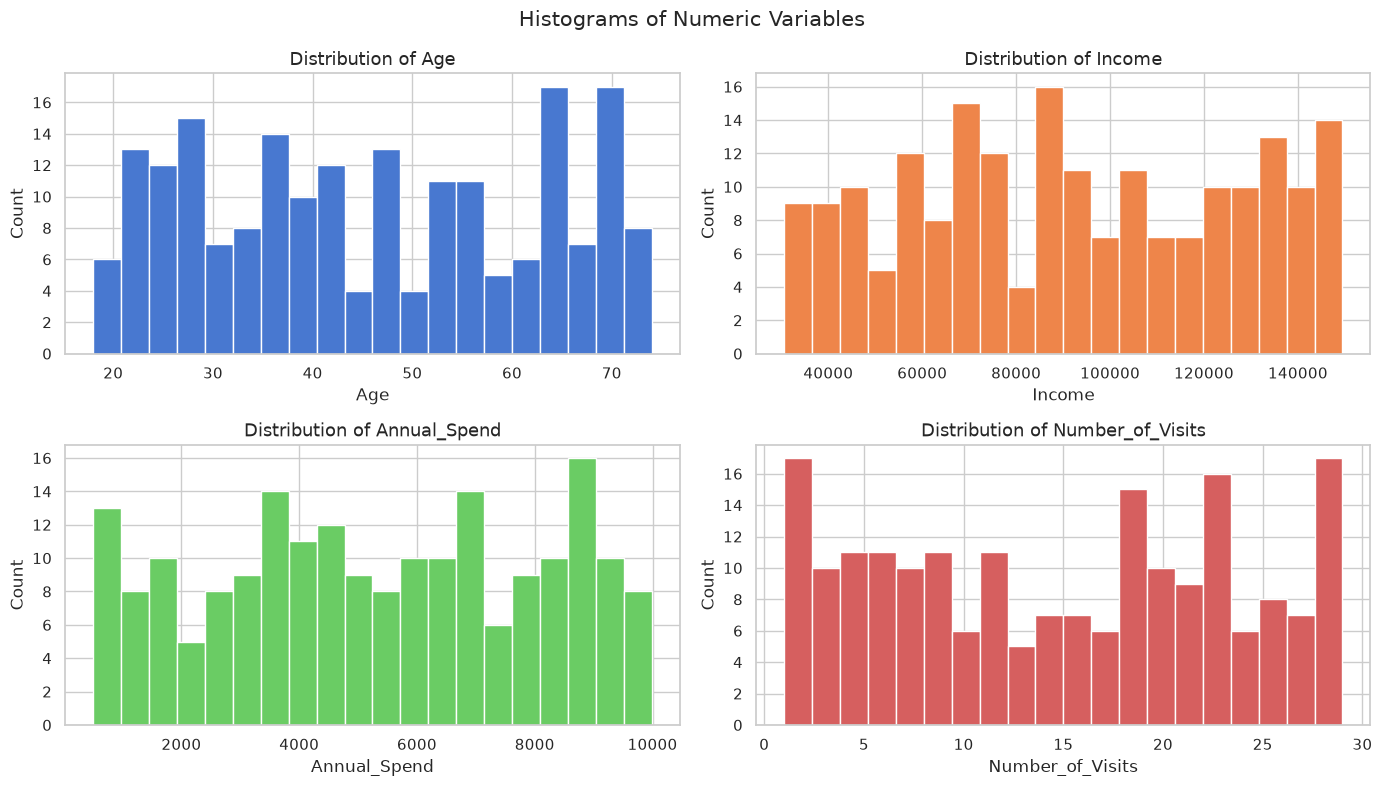

In [6]:
numeric_cols = ['Age', 'Income', 'Annual_Spend', 'Number_of_Visits']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=20, edgecolor='white', color=sns.color_palette('muted')[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=13)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.suptitle('Histograms of Numeric Variables', fontsize=15)
plt.tight_layout()
plt.show()

### 2.3 Categorical Variables (Bar Charts)

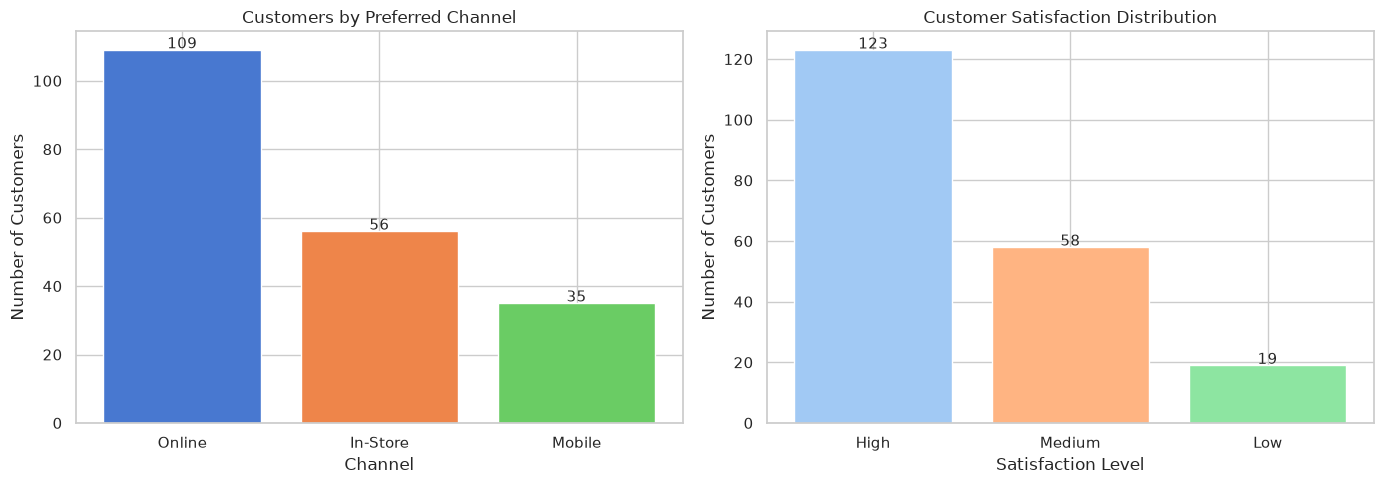

In [7]:
# categorical_cols = ['Preferred_Channel', 'Customer_Satisfaction]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Channel Distribution
channel_counts = df['Preferred_Channel'].value_counts()
ax1.bar(x=channel_counts.index, height=channel_counts.values, color=sns.color_palette('muted'))
ax1.set_title("Customers by Preferred Channel")
ax1.set_xlabel('Channel')
ax1.set_ylabel('Number of Customers')

for i, v in enumerate(channel_counts.values):
    ax1.text(x=i, y=v+0.5, s=str(v), ha='center', fontsize=11)

# Satisfaction Distribution
satisfaction_counts = df['Customer_Satisfaction'].value_counts()
ax2.bar(x=satisfaction_counts.index, height=satisfaction_counts.values, color=sns.color_palette('pastel'))
ax2.set(
    title='Customer Satisfaction Distribution',
    xlabel='Satisfaction Level',
    ylabel='Number of Customers'
)
for i, v in enumerate(satisfaction_counts.values):
    ax2.text(x=i, y=v+0.5, s=str(v), ha='center', fontsize=11)

plt.tight_layout()
plt.show()

### 2.4 Relationships - Scatterplots

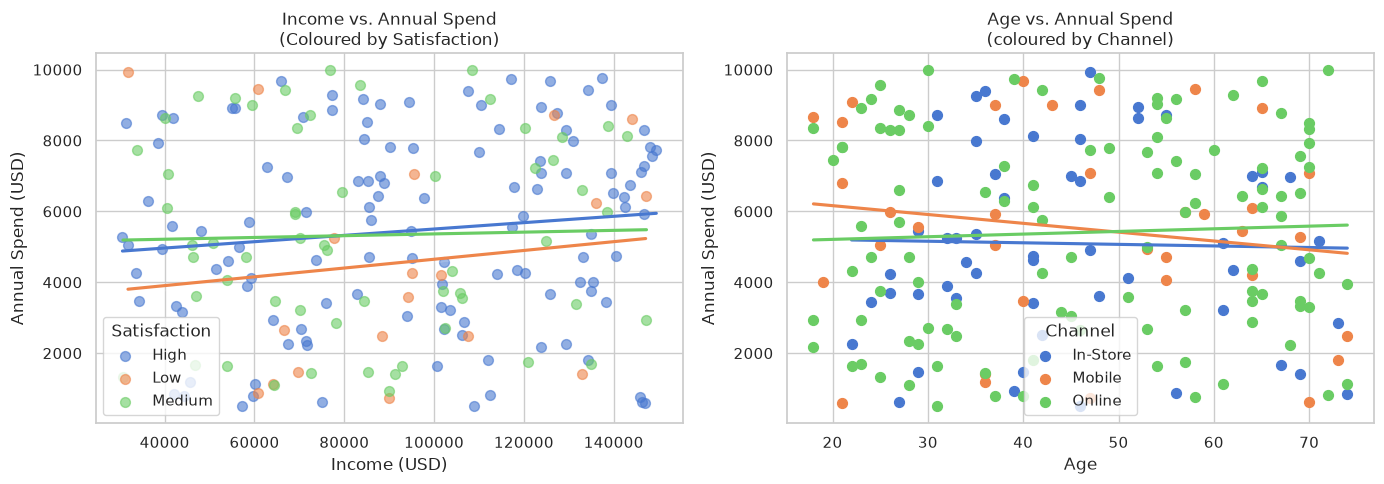

In [8]:
# income - annual spend
# age - annual spend

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Income vs Annual_Spend - coloured by satisfaction
for sat, grp in df.groupby('Customer_Satisfaction'):
    axes[0].scatter(x=grp['Income'], y=grp['Annual_Spend'], label=sat, alpha=0.6, s=50)
    sns.regplot(data=grp, x='Income', y='Annual_Spend', ax=axes[0], scatter=False, ci=False)
axes[0].set(
    title='Income vs. Annual Spend\n(Coloured by Satisfaction)',
    xlabel='Income (USD)',
    ylabel='Annual Spend (USD)'
)
axes[0].legend(title='Satisfaction')


# Age vs Annual_Spend - Colored by Channel
for channel, grp in df.groupby('Preferred_Channel'):
    axes[1].scatter(x=grp['Age'], y=grp['Annual_Spend'], label=channel, s=50)
    sns.regplot(data=grp, x='Age', y='Annual_Spend', ax=axes[1], scatter=False, ci=False)
axes[1].set(
    title='Age vs. Annual Spend\n(coloured by Channel)',
    xlabel='Age',
    ylabel='Annual Spend (USD)'
)
axes[1].legend(title='Channel')

plt.tight_layout()
plt.show()

### 2.5 Correlation Heatmap:

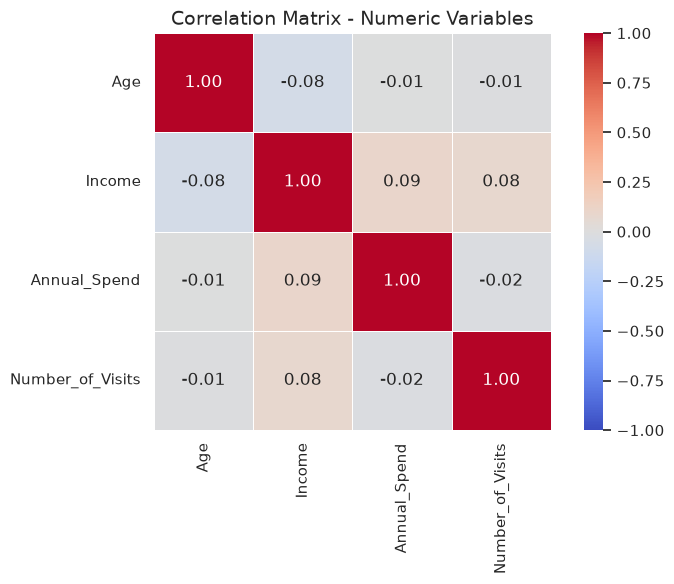

In [9]:
numeric_df = df[['Age', 'Income', 'Annual_Spend', 'Number_of_Visits']]
corr = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(data=corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5, vmin=-1, vmax=1)

plt.title('Correlation Matrix - Numeric Variables', fontsize=14)
plt.tight_layout()
plt.show()

### 2.6 Average Annual Spend by Satisfaction & Channel

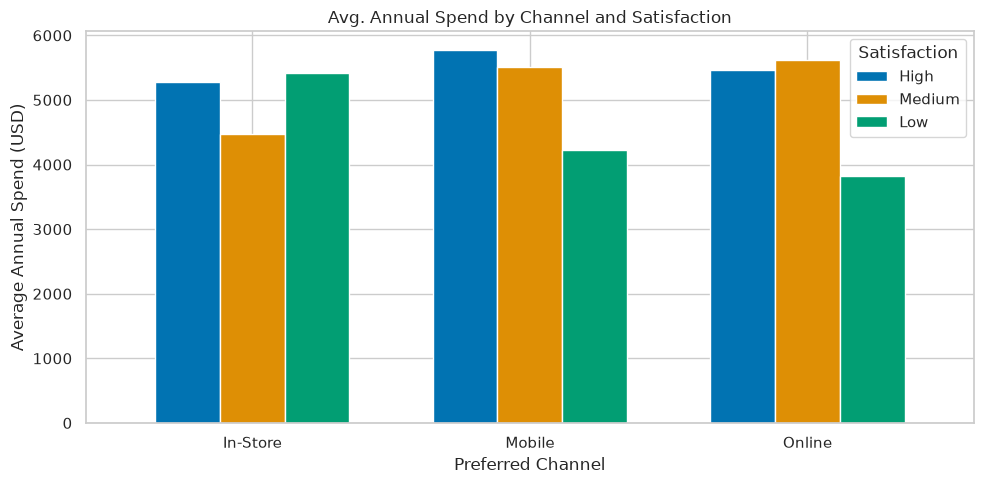

In [10]:
pivot = df.groupby(['Preferred_Channel', 'Customer_Satisfaction'])['Annual_Spend'].mean().unstack()
pivot = pivot[['High', 'Medium', 'Low']]

pivot.plot(kind='bar', figsize=(10, 5), color=sns.color_palette('colorblind'), edgecolor='white', width=0.7)
plt.title('Avg. Annual Spend by Channel and Satisfaction')
plt.xlabel('Preferred Channel')
plt.ylabel('Average Annual Spend (USD)')
plt.xticks(rotation=0)
plt.legend(title='Satisfaction')
plt.tight_layout()
plt.show()

### 2.7 EDA Commentary
**Dataset Overview:**  
The dataset contains 200 records and 7 variables describing customer demographics, income, annual spending, purchasing behaviour, and preferred purchasing channel, and satisfaction. Initial inspection identified zero missing values across all fields.  

**Univariate Analysis:**  
Descriptive Statistics show considerable variations among customers. Ages range between 18 and 47, with an average of 45.86. Income ranges from $30.6k to $149.5k with the average income at $92.2k. The annual spending range between $500 and around 10k with average value of $5.3k, customers made an average of 14.72 visits with values ranging from 1 to 29. These differences show the dataset represents customers with varying demographic and purchasing characterstics.  
Customer sentiment is generally positive showing 61.5% of customers highly satisfied, 29% medium and 9.5% low. The purchaing channel preference skews digital with 54.5% shopping online, 28% in-store, and 17.5% mobile.  

**Bi-variate Analysis:**  
Scatterplot visualzations segmented by categorical features reveal some underlying behaviours.  
The plot of `income vs annual spend colored by satisfaction` isolates how spending scales with earnings across different satisfaction tiers.  
`Age vs annual spending colored by channel` further maps demographic engagement.  
The correlation matrix quantifies the linear relationships bwtween the numeric features.

---
## 3. Decision Tree: Predict Customer_Satisfaction

### 3.1 Pre processing for models
Machine learning models only deal with numeric values.  
Encode the categorical columns

In [11]:
# LabelEncoder maps each unique String to an integer
# e.g. 'High' -> 0, 'Low' -> 1, 'Medium' -> 1   (Alphabetical by default)

df_model = df.copy()

le_channel = LabelEncoder()
df_model['Preferred_Channel_enc'] = le_channel.fit_transform(y=df_model['Preferred_Channel'])
print('Channel Mapping: ', dict(zip(le_channel.classes_, le_channel.transform(le_channel.classes_))))
print(sorted(df_model['Preferred_Channel'].unique()))
print(sorted(df_model['Preferred_Channel_enc'].unique()))

le_sat = LabelEncoder()
df_model['Customer_Satisfaction_enc'] = le_sat.fit_transform(df_model['Customer_Satisfaction'])
print('Satisfaction mapping:', dict(zip(le_sat.classes_, le_sat.transform(le_sat.classes_))))

Channel Mapping:  {'In-Store': np.int64(0), 'Mobile': np.int64(1), 'Online': np.int64(2)}
['In-Store', 'Mobile', 'Online']
[np.int64(0), np.int64(1), np.int64(2)]
Satisfaction mapping: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}


### 3.2 Define Features & Target, and Split Data
start with 80/20 train-test split

In [12]:
FEATURES_DT = ['Age', 'Income', 'Annual_Spend', 'Number_of_Visits', 'Preferred_Channel_enc']
TARGET_DT   = 'Customer_Satisfaction_enc'

X_dt = df_model[FEATURES_DT]
y_dt = df_model[TARGET_DT]

X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(X_dt, y_dt, test_size=0.2, random_state=42, stratify=y_dt)

print(f'Training samples : {len(X_train_dt)}')
print(f'Test samples     : {len(X_test_dt)}')

Training samples : 160
Test samples     : 40


### 3.3 Train the Decision Tree

First 10 actual labels: [0, 1, 1, 0, 2, 0, 2, 0, 2, 2]
First 10 predictions: [0, 0, 0, 0, 0, 0, 0, 0, 2, 0]
Test Accuracy: 65.00%

Classification Report: 
              precision    recall  f1-score   support

        High       0.67      0.92      0.77        24
         Low       0.00      0.00      0.00         4
      Medium       0.57      0.33      0.42        12

    accuracy                           0.65        40
   macro avg       0.41      0.42      0.40        40
weighted avg       0.57      0.65      0.59        40

=== Confusion Matrix ===


/home/mabdelkawy/dev/data-analysis-msc/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mabdelkawy/dev/data-analysis-msc/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mabdelkawy/dev/data-analysis-msc/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

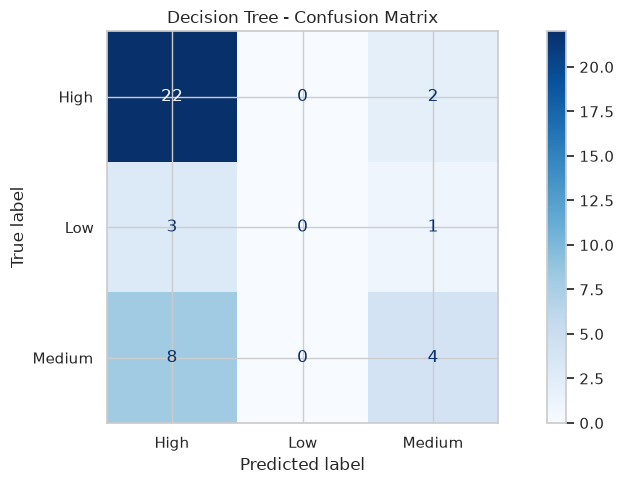

In [13]:
dt_model = DecisionTreeClassifier(
    max_depth=4,
    criterion='gini',
    random_state=42
)

dt_model.fit(X_train_dt, y_train_dt)

y_pred_dt = dt_model.predict(X=X_test_dt)

print("First 10 actual labels:", y_test_dt.iloc[:10].tolist())
print("First 10 predictions:", y_pred_dt[:10].tolist())

acc = accuracy_score(y_true=y_test_dt, y_pred = y_pred_dt)
print(f'Test Accuracy: {acc:.2%}')
print('\nClassification Report: ')
print(classification_report(y_true=y_test_dt, y_pred=y_pred_dt, target_names=le_sat.classes_))

print('=== Confusion Matrix ===')
cm = confusion_matrix(y_test_dt, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_sat.classes_
)

disp.plot(cmap='Blues')
plt.title('Decision Tree - Confusion Matrix')
plt.tight_layout()
plt.show()

### 3.4 Visualize the Decision Tree:

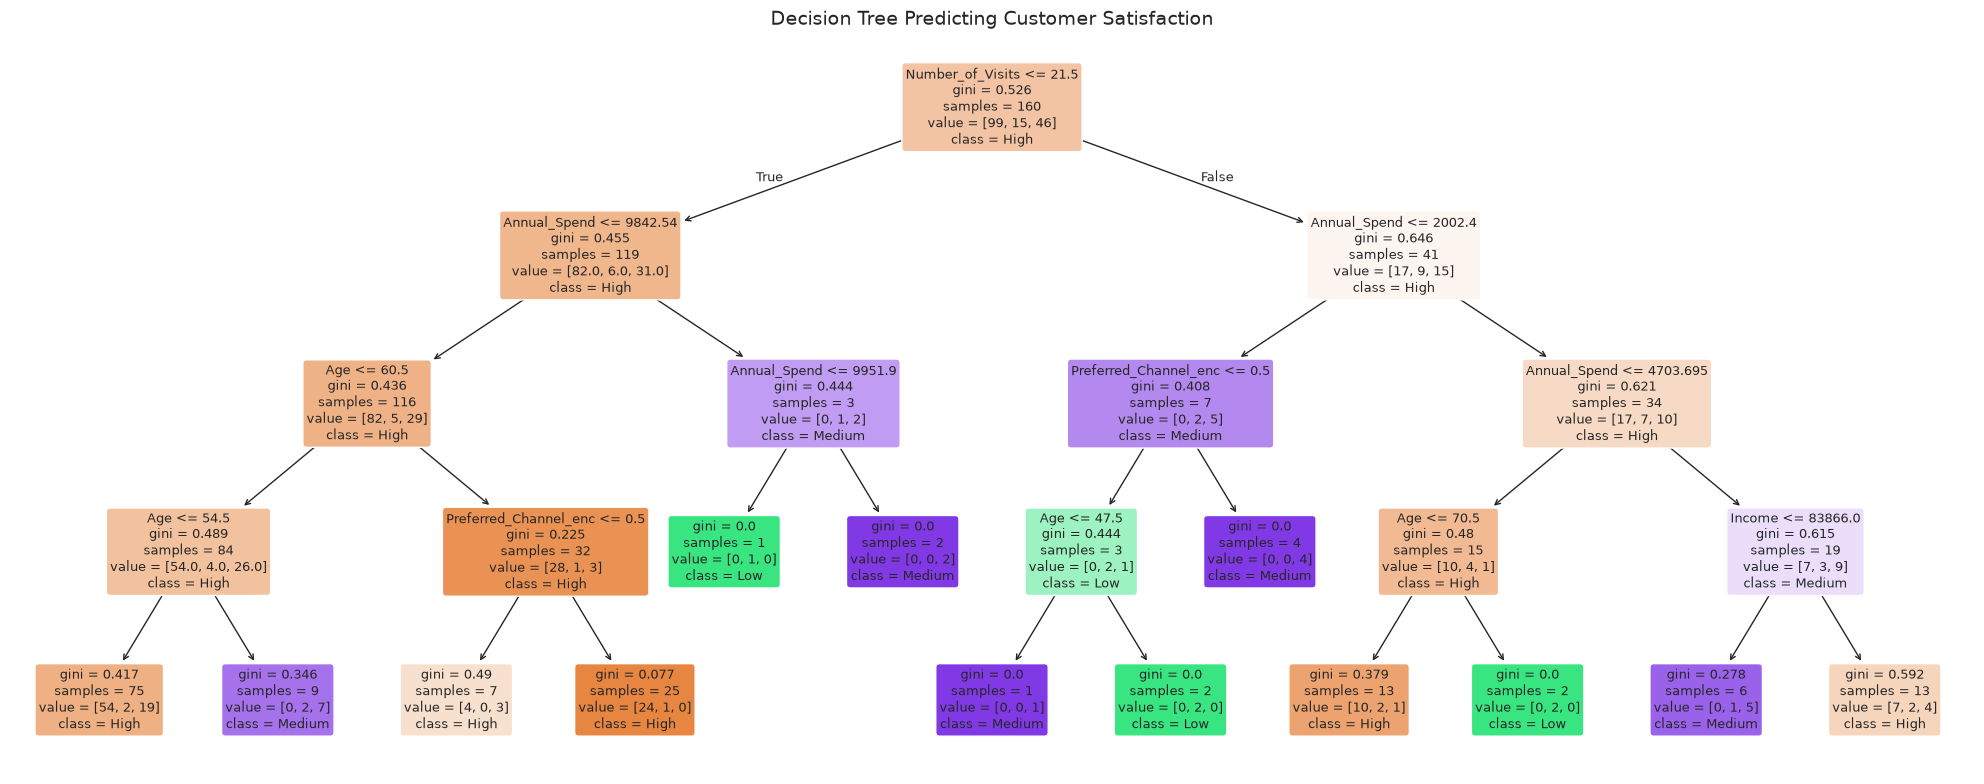

In [14]:
plt.figure(figsize=(20, 8))
plot_tree(
    decision_tree=dt_model,
    feature_names=FEATURES_DT,
    class_names=le_sat.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Predicting Customer Satisfaction", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
# text representation of the tree
print(export_text(decision_tree=dt_model, feature_names=FEATURES_DT))

|--- Number_of_Visits <= 21.50
|   |--- Annual_Spend <= 9842.54
|   |   |--- Age <= 60.50
|   |   |   |--- Age <= 54.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  54.50
|   |   |   |   |--- class: 2
|   |   |--- Age >  60.50
|   |   |   |--- Preferred_Channel_enc <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Preferred_Channel_enc >  0.50
|   |   |   |   |--- class: 0
|   |--- Annual_Spend >  9842.54
|   |   |--- Annual_Spend <= 9951.90
|   |   |   |--- class: 1
|   |   |--- Annual_Spend >  9951.90
|   |   |   |--- class: 2
|--- Number_of_Visits >  21.50
|   |--- Annual_Spend <= 2002.40
|   |   |--- Preferred_Channel_enc <= 0.50
|   |   |   |--- Age <= 47.50
|   |   |   |   |--- class: 2
|   |   |   |--- Age >  47.50
|   |   |   |   |--- class: 1
|   |   |--- Preferred_Channel_enc >  0.50
|   |   |   |--- class: 2
|   |--- Annual_Spend >  2002.40
|   |   |--- Annual_Spend <= 4703.70
|   |   |   |--- Age <= 70.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  7

### 3.5 Feature Importance

The tree relied on most hight importance = strong predictor of satisfaction.

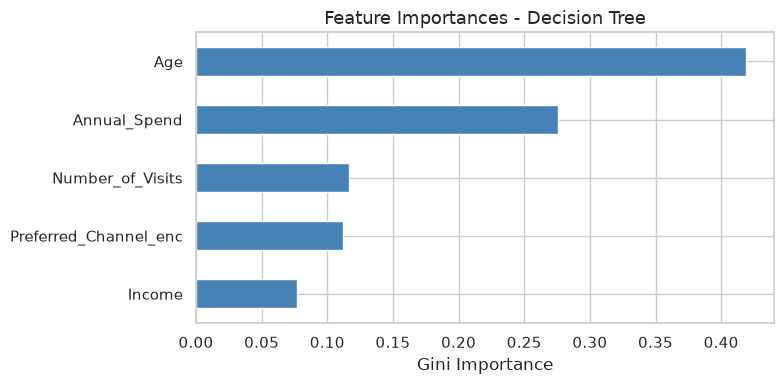

Age                      0.419268
Annual_Spend             0.275426
Number_of_Visits         0.116446
Preferred_Channel_enc    0.111654
Income                   0.077206
dtype: float64


In [16]:
importances = pd.Series(dt_model.feature_importances_, index=FEATURES_DT).sort_values(ascending=True)

importances.plot(kind='barh', figsize=(8, 4), color='steelblue')

plt.title('Feature Importances - Decision Tree', fontsize=13)
plt.xlabel('Gini Importance')
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

### 3.6 Decision Tree Commentary:
A decision tree calssifier was developed to predict `Customer_Satisfaction` using Age, Income, Annual_Spend, Number_of_Visits, and Preferred_Channel. The dataset was divided into 2 subsets, 80% for training and 20% for testing, using stratified sampling to preserve the distribution of satisfaction categories.  

The model achieved 65% accuracy on the test dataset, correctly classifying 26 out of 40 customers. However, its performance varied across satisfaction categories. Recall was 92% for high satisfaction,, 33% for medium and 0% for low. The model therefore struggled to identify customers with lower satisfaction levels.

The result could be interpreted in light of the impalanced representaion of satisfaction categories in the dataset. High satisfaction is 61.5% of the complete dataset. A baseline classifier that always predicts high would achieve 60% accuracy on this dataset. Consequently, the 65% accuracy by this decision tree model provided slight improvement over the baseline.

Feature importance indicated that Age (41.93%) and Annual_Spend (27.54%) contributed the most to the trees impurity reduction, followed by Number_of_Visits (11.64%), Preferred_Channel (11.17%), and Income (7.72%). These values describe the fitted model's reliance on the predictors. yet do not necessarily establish a causal relationship.  

Overall, the decision tree demonstrated how customer characteristics can be used to predict customer satisfaction, yet its limited ability to identify medium and low satisfaction levels suggest that its predictive performance is not sufficiently reliable for identifying dissatisfied customers.

---
## 4. Linear Regression: Predicting Annual_Spend

### 4.1 Define Features and Target

The objective is to predict customer annual spending (`Annual_Spend`) using four independent variables:

- `Age`
- `Income`
- `Number_of_Visits`
- `Preferred_Channel_enc`

This is a **multiple linear regression** problem because the model uses multiple predictors to estimate a continuous numerical outcome.

The model can be expressed as:

$$
\begin{aligned}
\widehat{\text{Annual Spend}} ={}&
b_0 + b_1(\text{Age}) + b_2(\text{Income})\\
&+ b_3(\text{Number of Visits})
+ b_4(\text{Preferred Channel})
\end{aligned}
$$

Where:
- **Annual Spend:** The target variable we want to predict.
- **$b_0$ (Intercept):** The predicted spending when all predictors are zero.
- **$b_1$–$b_4$ (Coefficients):** The expected change in spending for a one-unit increase in each predictor, holding the others constant.

`CustomerID` is excluded because it is an identifier, not a meaningful predictor. `Customer_Satisfaction` is also excluded because it is not part of this model's selected predictors.


In [17]:
FEATURES_LR = ['Age', 'Income', 'Number_of_Visits', 'Preferred_Channel_enc']
TARGET_LR   = 'Annual_Spend'

X_lr = df_model[FEATURES_LR] # predictors
y_lr = df_model[TARGET_LR] # target

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr, y_lr, test_size=0.2, random_state=42
)

print(f'Training samples : {len(X_train_lr)}')
print(f'Test samples     : {len(X_test_lr)}')

Training samples : 160
Test samples     : 40


### 4.2 Train and Evaluate

LinearRegression() fits: Annual_Spend = b0 + b1*Age + b2*Income + ...  
Key metrics:  
- R²  → proportion of variance explained (0–1; higher is better)  
- RMSE → average prediction error in the same unit as Annual_Spend (USD)



In [18]:
lr_model = LinearRegression()
lr_model.fit(X_train_lr, y_train_lr)

y_pred_lr = lr_model.predict(X_test_lr)

r2   = r2_score(y_test_lr, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test_lr, y_pred_lr))

print(f'R²   = {r2:.4f}  → the model explains {r2*100:.1f}% of variance in Annual_Spend')
print(f'RMSE = {rmse:.2f} USD  → average prediction error')

baseline_prediction = y_train_lr.mean()
y_baseline = np.full(len(y_test_lr), baseline_prediction)
baseline_r2 = r2_score(y_test_lr, y_baseline)
print(baseline_r2)

R²   = -0.0464  → the model explains -4.6% of variance in Annual_Spend
RMSE = 2594.83 USD  → average prediction error
-0.004447685994293016


### 4.3 Coefficients Table

Coeffiecients tell:  
Positive coefficient → feature increases Annual_Spend  
Negative coefficient → feature decreases Annual_Spend  
The magnitude matters: a coefficient of 0.05 on Income means  
'each extra $1 of income adds $0.05 to annual spend (all else equal)'.

In [19]:
coef_df = pd.DataFrame({
    'Feature'    : ['Intercept'] + FEATURES_LR,
    'Coefficient': [lr_model.intercept_] + list(lr_model.coef_)
}).round(4)

print(coef_df.to_string(index=False))

              Feature  Coefficient
            Intercept    5050.2624
                  Age       0.7639
               Income       0.0047
     Number_of_Visits     -28.6800
Preferred_Channel_enc     222.1910


### 4.4 Visualize: Actual vs. Predicted
If the model were perfect, all points would sit on the y = x line (the diagonal).  
A wide scatter indicates high error. Points systematically above/below  
the line hint at bias (the model consistently over- or under-predicts).

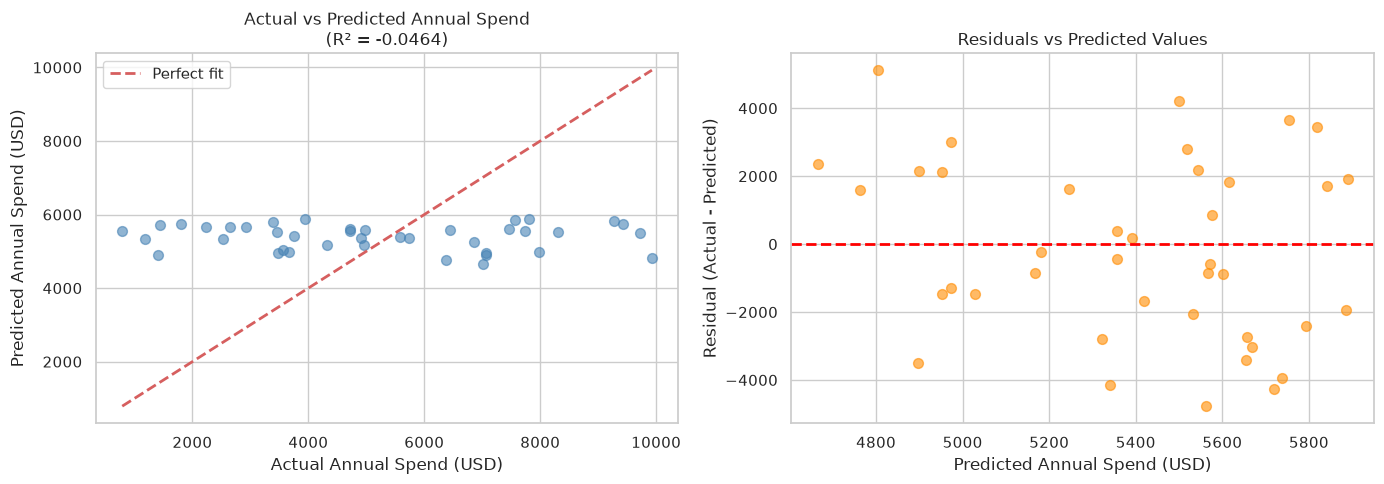

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs predicted
ax1.scatter(x=y_test_lr, y=y_pred_lr, alpha=0.6, color='steelblue', s=50)
min_val = min(y_test_lr.min(), y_pred_lr.min())
max_val = max(y_test_lr.max(), y_pred_lr.max())
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect fit')

ax1.set_title(f'Actual vs Predicted Annual Spend\n(R² = {r2:.4f})', fontsize=12)
ax1.set_xlabel('Actual Annual Spend (USD)')
ax1.set_ylabel('Predicted Annual Spend (USD)')
ax1.legend()

# Residual plot
residuals = y_test_lr - y_pred_lr
ax2.scatter(y_pred_lr, residuals, alpha=0.6, color='darkorange', s=50)
ax2.axhline(0, color='red', linestyle='--', lw=2)
ax2.set_title('Residuals vs Predicted Values', fontsize=12)
ax2.set_xlabel('Predicted Annual Spend (USD)')
ax2.set_ylabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.show()

### 4.5 Coefficients Bar Chart

 This chart shows the direction and relative size of each coefficient.  
 It's clearer than a table when we have many features.

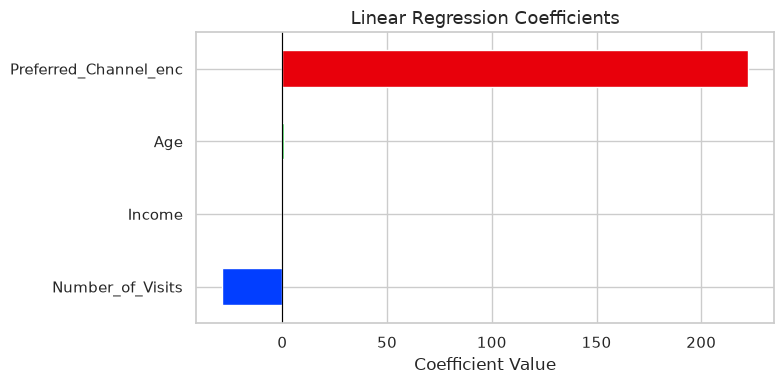

In [21]:
coef_plot = pd.Series(lr_model.coef_, index=FEATURES_LR).sort_values()

coef_plot.plot(kind='barh', color=sns.color_palette('bright'), figsize=(8, 4))
plt.axvline(0, color='black', lw=0.8)
plt.title('Linear Regression Coefficients', fontsize=13)
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

### 4.6 Regression model commentary:
A multiple linear regressoin model was created to predict Annual_Spend using Age, Income, Number_of_Visits, and Preferred_Channel. The model achieved R-squared of -0.0464 and an RMSE of $2.6k. The negative R-squared indicates that the model performed worse than a baseline that predicts the training set average spending for every test observation. The coefficients indicated positive associations for Age and Income and a negative association for Number_of_Visits, yet they do not establish causal relationships. The categorical shopping channel was numerically encoded, which may also have affected the model's suitability